# 1.2 Experimentos de ingeniería de datos: análisis y decisión

Análisis de las corridas definidas en `1.2_ingenieria_datos.ipynb` (sección 7) y entrenadas en Colab con `nube/1.2_experimentos_colab.ipynb`:

| Factor | Niveles |
| :--- | :--- |
| Resolución | 640, 960 y 1280 px |
| Fotométrico | `base` (sin corrección), `norm` (Gray World) |
| Balanceo | `sinbal`, `bal` (copias de la clase deficitaria) |

Las 12 configuraciones se entrenan en cada uno de los 4 pliegues con las semillas 13, 29 y 51: **144 corridas**. Cada corrida entrena con tres pliegues y se evalúa en el cuarto. El conjunto de prueba no interviene.

**Regla de decisión** (fijada antes de entrenar): se parte de la configuración más simple (640, `base`, `sinbal`), y un nivel más costoso o complejo solo se adopta si mejora el mAP50-95 en al menos **+0.005** y la mejora es **significativa** (p < 0.05). Si alguna interacción es significativa, se comparan configuraciones completas (`comun.decidir`).

**Experimentos complementarios** (sección 8): sobre la configuración elegida, se entrena quitando la limpieza de etiquetas o el aumento en línea, 12 corridas cada uno.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

RAIZ = Path.cwd(); sys.path.insert(0, str(RAIZ))
import comun as C

C.estilo()
part = json.loads((RAIZ / 'resultados' / 'particion.json').read_text())
REGISTRO = RAIZ / 'resultados' / 'experimentos.csv'
SALIDA = RAIZ / 'salida' / '1.2_experimentos'

## 1. Integración de las corridas

Incorpora las descargas de Colab (`oe1_runs_*`, en zip o ya extraídas, en la raíz del repositorio, en `nube/` o en `~/Downloads`): sus corridas pasan a `runs/oe1/` y sus filas a `resultados/experimentos.csv`, sin duplicar. Volver a ejecutar esta celda no cambia nada.

In [2]:
descargas = sorted({p for base in (C.REPO, C.NUBE, Path.home() / 'Downloads') for p in base.glob('oe1_runs_*')
                    if p.suffix == '.zip' or (p / 'oe1' / 'resultados' / 'experimentos.csv').exists()})
for descarga in descargas:
    print(f'{descarga.name}: {len(C.integrar_descarga(descarga, REGISTRO))} corridas')
if not descargas:
    print('No hay descargas que integrar.')
todas = pd.read_csv(REGISTRO).drop_duplicates('id', keep='last')
if 'complementario' not in todas:
    todas['complementario'] = np.nan
df = todas[todas['complementario'].isna()]   # diseño factorial; los complementarios van en la sección 8
print(f"{len(todas)} corridas en el registro: {len(df)} del diseño factorial | GPU: {', '.join(todas.gpu.unique())} | "
      f"{todas.minutos.sum() / 60:.1f} h de entrenamiento")

oe1_runs_complementarios_s13_29_51: 168 corridas
oe1_runs_factorial_s13: 48 corridas


oe1_runs_factorial_s29_51: 96 corridas


oe1_runs_complementarios_s13_29_51.zip: 168 corridas


oe1_runs_factorial_s13.zip: 48 corridas


oe1_runs_factorial_s29_51.zip: 96 corridas
168 corridas en el registro: 144 del diseño factorial | GPU: NVIDIA A100-SXM4-40GB | 12.0 h de entrenamiento


## 2. Completitud del diseño

Cada configuración debe tener exactamente una corrida por pliegue y semilla. Si falta alguna, el análisis no es definitivo.

In [3]:
completitud = pd.crosstab([df.resolucion, df.fotometrico, df.balanceo], [df.semilla, df.pliegue])
COMPLETO = completitud.shape == (len(C.configuraciones()), len(C.SEMILLAS) * part['k']) and (completitud.values == 1).all()
print('Diseño completo' if COMPLETO else 'FALTAN corridas: el análisis no es definitivo.')
completitud

Diseño completo


semilla                         13          29          51         
pliegue                          0  1  2  3  0  1  2  3  0  1  2  3
resolucion fotometrico balanceo                                    
640        base        bal       1  1  1  1  1  1  1  1  1  1  1  1
                       sinbal    1  1  1  1  1  1  1  1  1  1  1  1
           norm        bal       1  1  1  1  1  1  1  1  1  1  1  1
                       sinbal    1  1  1  1  1  1  1  1  1  1  1  1
960        base        bal       1  1  1  1  1  1  1  1  1  1  1  1
                       sinbal    1  1  1  1  1  1  1  1  1  1  1  1
           norm        bal       1  1  1  1  1  1  1  1  1  1  1  1
                       sinbal    1  1  1  1  1  1  1  1  1  1  1  1
1280       base        bal       1  1  1  1  1  1  1  1  1  1  1  1
                       sinbal    1  1  1  1  1  1  1  1  1  1  1  1
           norm        bal       1  1  1  1  1  1  1  1  1  1  1  1
                       sinbal    1  1  1  1  1  1  1  1  1  1  1  1

## 3. ¿Qué factores influyen?

Modelo lineal sobre el mAP50-95 con los tres factores, todas sus interacciones y cada combinación de pliegue y semilla como bloque. El bloque descuenta la diferencia de dificultad entre pliegues y la variación entre semillas, de modo que cada factor se evalúa comparando configuraciones con el mismo pliegue y la misma semilla.

Para cada factor y cada combinación de factores (interacción), indica si cambia el mAP50-95 de forma significativa. Una interacción significativa indicaría que el efecto de un factor depende del nivel de otro; en ese caso, los factores no se deciden por separado.

In [4]:
C.anova(df, 'mAP50_95').round(4)

,factor,valor p,influye
0,resolucion,0.0000,Sí
1,fotometrico,0.0013,Sí
2,balanceo,0.9762,No
3,resolucion x fotometrico,0.9748,No
4,resolucion x balanceo,0.9635,No
5,fotometrico x balanceo,0.9458,No
6,resolucion x fotometrico x balanceo,0.9356,No


## 4. Diferencias entre niveles

**Cómo leer la tabla:**
- **Diferencia:** cuánto cambia el mAP50-95 medio al pasar de un nivel a otro (por ejemplo, de 960 a 1280), promediando los demás factores. Positiva = mejora.
- **Valor p:** probabilidad de observar una diferencia así por azar, si en realidad no la hubiera. Por debajo de 0.05, la diferencia se considera **significativa**.
- **Rango probable:** intervalo de confianza del 95 %. En el gráfico, la línea roja marca la mejora mínima de la regla (+0.005).

,comparación,diferencia,mínimo probable,máximo probable,valor p,significativo
0,resolucion: 960 - 640,0.0181,0.0122,0.0240,0.0000,Sí
1,resolucion: 1280 - 640,0.0261,0.0202,0.0320,0.0000,Sí
2,resolucion: 1280 - 960,0.0080,0.0021,0.0139,0.0081,Sí
3,fotometrico: norm - base,0.0080,0.0032,0.0128,0.0013,Sí
4,balanceo: bal - sinbal,0.0001,-0.0047,0.0049,0.9762,No


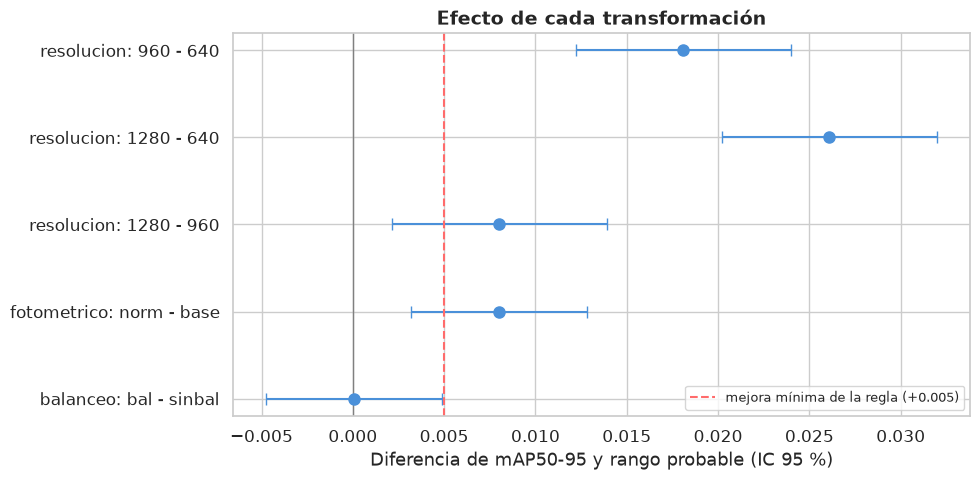

In [5]:
tabla = C.analizar(df, 'mAP50_95')
display(tabla.round(4))
t = tabla.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(t['diferencia'], range(len(t)), xerr=[t['diferencia'] - t['mínimo probable'], t['máximo probable'] - t['diferencia']],
            fmt='o', color='#4A90D9', capsize=4, markersize=8)
ax.axvline(0, color='grey', lw=1); ax.axvline(C.GANANCIA_MIN, color='#FF6B6B', ls='--', label=f'mejora mínima de la regla (+{C.GANANCIA_MIN})')
ax.set_yticks(range(len(t))); ax.set_yticklabels(t['comparación']); ax.set_xlabel('Diferencia de mAP50-95 y rango probable (IC 95 %)')
ax.set_title('Efecto de cada transformación'); ax.legend(fontsize=9)
C.guardar(SALIDA, 'efectos_transformaciones.png')

## 5. Medias por configuración

Promedio de los 4 pliegues y las 3 semillas, y desviación estándar entre semillas (de la media de los 4 pliegues). El tiempo (`minutos`) muestra el costo de cada configuración. El gráfico muestra cómo cambia el mAP50-95 con la resolución en cada combinación de los otros dos factores: líneas paralelas indican que no hay interacción.

mAP50_95   mAP50  precision  recall  \
resolucion fotometrico balanceo                                        
1280       norm        sinbal      0.7446  0.9771     0.9238  0.9585   
                       bal         0.7444  0.9753     0.9232  0.9585   
           base        sinbal      0.7378  0.9738     0.9214  0.9532   
960        norm        sinbal      0.7371  0.9750     0.9246  0.9566   
1280       base        bal         0.7363  0.9719     0.9102  0.9597   
960        norm        bal         0.7362  0.9734     0.9217  0.9549   
           base        bal         0.7295  0.9707     0.9191  0.9499   
                       sinbal      0.7282  0.9682     0.9129  0.9578   
640        norm        bal         0.7199  0.9711     0.9100  0.9439   
                       sinbal      0.7182  0.9693     0.9056  0.9523   
           base        sinbal      0.7104  0.9615     0.9007  0.9440   
                       bal         0.7102  0.9644     0.9007  0.9467   

                                 mae_conteo  minutos  sd entre semillas  
resolucion fotometrico balanceo                                          
1280       norm        sinbal        0.3531   4.9333             0.0032  
                       bal           0.3494   4.9250             0.0056  
           base        sinbal        0.3587   4.8333             0.0058  
960        norm        sinbal        0.4632   4.0833             0.0012  
1280       base        bal           0.3259   4.9333             0.0042  
960        norm        bal           0.4373   4.1250             0.0097  
           base        bal           0.4505   4.1083             0.0066  
                       sinbal        0.3983   4.0833             0.0030  
640        norm        bal           0.6535   3.6333             0.0027  
                       sinbal        0.5945   3.6167             0.0034  
           base        sinbal        0.7154   3.6833             0.0073  
                       bal           0.7425   3.6250             0.0080

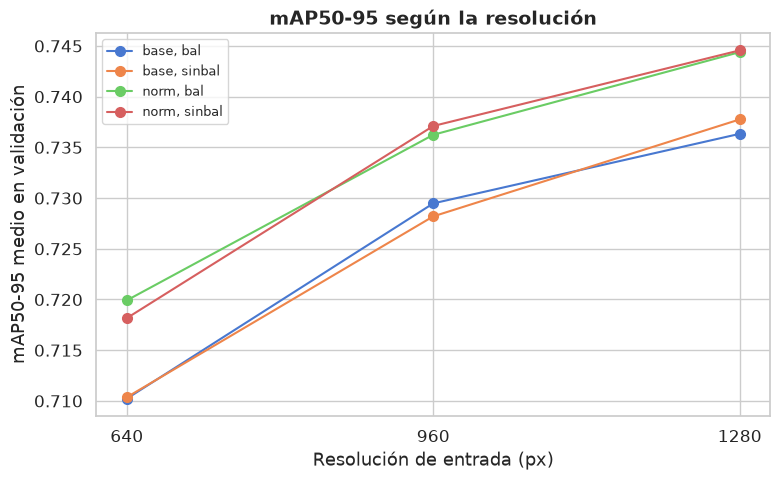

In [6]:
cfg = ['resolucion', 'fotometrico', 'balanceo']
medias = df.groupby(cfg)[['mAP50_95', 'mAP50', 'precision', 'recall', 'mae_conteo', 'minutos']].mean()
medias['sd entre semillas'] = df.groupby(cfg + ['semilla']).mAP50_95.mean().groupby(cfg).std(ddof=1)
display(medias.round(4).sort_values('mAP50_95', ascending=False))
fig, ax = plt.subplots(figsize=(8, 5))
for (foto, bal), g in df.groupby(['fotometrico', 'balanceo']):
    m = g.groupby('resolucion').mAP50_95.mean()
    ax.plot(m.index.astype(str), m.values, 'o-', markersize=7, label=f'{foto}, {bal}')
ax.set_xlabel('Resolución de entrada (px)'); ax.set_ylabel('mAP50-95 medio en validación')
ax.set_title('mAP50-95 según la resolución'); ax.legend(fontsize=9)
C.guardar(SALIDA, 'medias_por_resolucion.png')

## 6. Otras métricas y subtipos

Las mismas comparaciones para las métricas secundarias. En el MAE de conteo, una diferencia negativa es una mejora. Después, la diferencia del acierto por subtipo entre niveles de cada factor: indica si una transformación favorece a algunos defectos a costa de otros. Los subtipos ausentes en un pliegue no cuentan en ese pliegue.

In [7]:
filas = []
for m in ['mAP50', 'precision', 'recall', 'mae_conteo']:
    filas.append(C.analizar(df, m).assign(métrica=m))
display(pd.concat(filas).set_index(['métrica', 'comparación']).drop(columns=['mínimo probable', 'máximo probable']).round(4))

subtipos = [f'acierto_{C.CLASES[i]}' for i in C.SUBTIPOS]
filas = []
for f, niveles in C.FACTORES.items():
    m = df.groupby(f)[subtipos].mean()
    for bajo, alto in zip(niveles, niveles[1:]):
        filas.append((m.loc[alto] - m.loc[bajo]).rename(f'{f}: {alto} - {bajo}'))
pd.DataFrame(filas).round(3)

diferencia  valor p significativo
métrica    comparación                                                
mAP50      resolucion: 960 - 640         0.0052   0.0212            Sí
           resolucion: 1280 - 640        0.0079   0.0006            Sí
           resolucion: 1280 - 960        0.0027   0.2339            No
           fotometrico: norm - base      0.0051   0.0063            Sí
           balanceo: bal - sinbal        0.0003   0.8632            No
precision  resolucion: 960 - 640         0.0153   0.0005            Sí
           resolucion: 1280 - 640        0.0154   0.0005            Sí
           resolucion: 1280 - 960        0.0001   0.9842            No
           fotometrico: norm - base      0.0073   0.0394            Sí
           balanceo: bal - sinbal       -0.0007   0.8387            No
recall     resolucion: 960 - 640         0.0081   0.0208            Sí
           resolucion: 1280 - 640        0.0107   0.0023            Sí
           resolucion: 1280 - 960        0.0026   0.4449            No
           fotometrico: norm - base      0.0022   0.4286            No
           balanceo: bal - sinbal       -0.0015   0.6003            No
mae_conteo resolucion: 960 - 640        -0.2392   0.0000            Sí
           resolucion: 1280 - 640       -0.3297   0.0000            Sí
           resolucion: 1280 - 960       -0.0905   0.0031            Sí
           fotometrico: norm - base     -0.0234   0.3419            No
           balanceo: bal - sinbal        0.0126   0.6068            No

,acierto_Broken,acierto_Damage,acierto_Fungus,acierto_Healthy,acierto_Immature,acierto_Shriveled,acierto_Weeveled
resolucion: 960 - 640,0.016,0.016,0.006,0.017,0.107,0.002,0.015
resolucion: 1280 - 960,-0.031,-0.028,0.000,0.005,0.018,-0.003,0.004
fotometrico: norm - base,0.024,0.001,-0.002,0.005,0.050,-0.002,-0.021
balanceo: bal - sinbal,0.032,0.022,0.006,-0.006,-0.075,0.001,0.012


## 7. Decisión

Se aplica la regla fijada antes de entrenar. Si el diseño está completo, la decisión se guarda en `resultados/decision.json` para los experimentos complementarios y la Actividad 1.3.

In [8]:
decision = C.decidir(df, 'mAP50_95')
print('Criterio:', decision['criterio'])
display(pd.DataFrame({f: {'elegido': decision[f]['elegido'], **{k: f"{v['diferencia']:+.4f} (p = {v['valor_p']:.3f})" for k, v in decision[f].items() if k != 'elegido'}}
                      for f in C.FACTORES}).T.fillna(''))
if 'pasos' in decision:
    for paso in decision['pasos']:
        print(paso)
if COMPLETO:
    (RAIZ / 'resultados' / 'decision.json').write_text(json.dumps(decision, indent=1, ensure_ascii=False, default=float))
    print('Decisión guardada en resultados/decision.json')

Criterio: efectos principales


,elegido,960 - 640,1280 - 960,norm - base,bal - sinbal
resolucion,1280,+0.0181 (p = 0.000),+0.0080 (p = 0.008),,
fotometrico,norm,,,+0.0080 (p = 0.001),
balanceo,sinbal,,,,+0.0001 (p = 0.976)


Decisión guardada en resultados/decision.json


## 8. Experimentos complementarios: limpieza y aumento

La limpieza de etiquetas y el aumento en línea se aplican sin pasar por el diseño factorial. Para comprobar su aporte, se entrena la configuración elegida **quitando cada técnica** y se compara, con el mismo pliegue y la misma semilla, con las corridas del diseño de esa configuración, que sí la incluyen:

- **Limpieza:** entrenamiento con las etiquetas originales (v0) en lugar de las corregidas. La validación usa siempre las etiquetas corregidas.
- **Aumento:** entrenamiento sin ningún aumento de Ultralytics (mosaico, volteo, escala, traslación, HSV y sus transformaciones de Albumentations).

La **diferencia** es *con la técnica − sin ella*: positiva = la técnica mejora (en el MAE de conteo, negativa = mejora). **Pares a favor** cuenta en cuántas de las 12 comparaciones (4 pliegues × 3 semillas) mejora. El valor p sale de una prueba t pareada.

con la técnica  \
técnica                                         métrica                      
Limpieza de etiquetas (corregidas − originales) mAP50_95            0.7446   
                                                mAP50               0.9771   
                                                precision           0.9238   
                                                recall              0.9585   
                                                mae_conteo          0.3531   
Aumento en línea (con − sin)                    mAP50_95            0.7446   
                                                mAP50               0.9771   
                                                precision           0.9238   
                                                recall              0.9585   
                                                mae_conteo          0.3531   

                                                            sin la técnica  \
técnica                                         métrica                      
Limpieza de etiquetas (corregidas − originales) mAP50_95            0.7191   
                                                mAP50               0.9546   
                                                precision           0.9100   
                                                recall              0.9466   
                                                mae_conteo          0.3792   
Aumento en línea (con − sin)                    mAP50_95            0.6780   
                                                mAP50               0.9440   
                                                precision           0.8841   
                                                recall              0.9173   
                                                mae_conteo          0.7471   

                                                            diferencia  \
técnica                                         métrica                  
Limpieza de etiquetas (corregidas − originales) mAP50_95        0.0255   
                                                mAP50           0.0226   
                                                precision       0.0137   
                                                recall          0.0119   
                                                mae_conteo     -0.0261   
Aumento en línea (con − sin)                    mAP50_95        0.0666   
                                                mAP50           0.0331   
                                                precision       0.0397   
                                                recall          0.0412   
                                                mae_conteo     -0.3940   

                                                           pares a favor  \
técnica                                         métrica                    
Limpieza de etiquetas (corregidas − originales) mAP50_95            8/12   
                                                mAP50               9/12   
                                                precision           8/12   
                                                recall              7/12   
                                                mae_conteo          6/12   
Aumento en línea (con − sin)                    mAP50_95           12/12   
                                                mAP50              12/12   
                                                precision           9/12   
                                                recall             11/12   
                                                mae_conteo         12/12   

                                                            valor p  \
técnica                                         métrica               
Limpieza de etiquetas (corregidas − originales) mAP50_95     0.0167   
                                                mAP50        0.0107   
                                                precision    0.3144   
                             

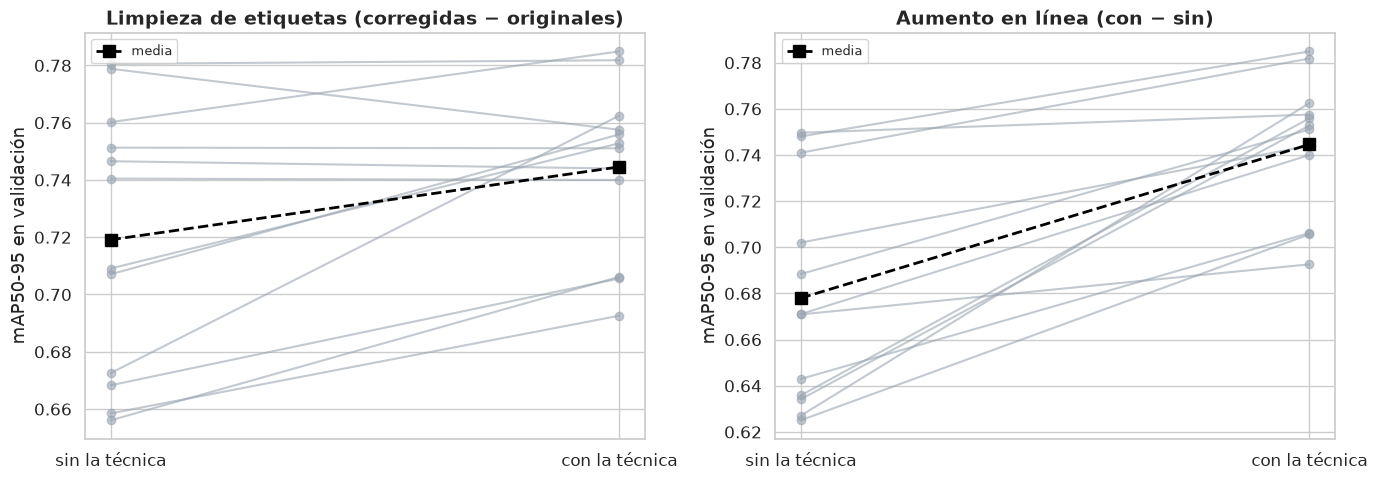

In [9]:
elegida = {f: decision[f]['elegido'] for f in C.FACTORES}
con = df[np.logical_and.reduce([df[f] == v for f, v in elegida.items()])].set_index(['pliegue', 'semilla']).sort_index()
metricas = {'mAP50_95': 1, 'mAP50': 1, 'precision': 1, 'recall': 1, 'mae_conteo': -1}   # -1: menor es mejor
filas, comparadas = [], {}
for comp, nombre in C.COMPLEMENTARIOS.items():
    sin = todas[todas['complementario'] == comp].set_index(['pliegue', 'semilla']).sort_index()
    if len(sin) < len(con):
        print(f'Pendiente: {comp} ({len(sin)} de {len(con)} corridas).'); continue
    comparadas[nombre] = sin
    for m, signo in metricas.items():
        d = con[m] - sin.loc[con.index, m]
        p = stats.ttest_rel(con[m], sin.loc[con.index, m]).pvalue
        filas.append({'técnica': nombre, 'métrica': m, 'con la técnica': con[m].mean(), 'sin la técnica': sin[m].mean(),
                      'diferencia': d.mean(), 'pares a favor': f'{(signo * d > 0).sum()}/{len(d)}',
                      'valor p': p, 'significativo': 'Sí' if p < 0.05 else 'No'})
if filas:
    display(pd.DataFrame(filas).set_index(['técnica', 'métrica']).round(4))
    fig, axes = plt.subplots(1, len(comparadas), figsize=(7 * len(comparadas), 5), squeeze=False)
    for ax, (nombre, sin) in zip(axes[0], comparadas.items()):
        for k in con.index:
            ax.plot(['sin la técnica', 'con la técnica'], [sin.loc[k, 'mAP50_95'], con.loc[k, 'mAP50_95']], 'o-', color='#9AA5B1', alpha=0.6)
        ax.plot(['sin la técnica', 'con la técnica'], [sin.mAP50_95.mean(), con.mAP50_95.mean()], 's--', color='black', lw=2, markersize=8, label='media')
        ax.set_title(nombre); ax.set_ylabel('mAP50-95 en validación'); ax.legend(fontsize=9)
    C.guardar(SALIDA, 'experimentos_complementarios.png')